In [ ]:
import sklearn.datasets as ds
import sklearn.model_selection as ms
import sklearn.ensemble as en
import sklearn.naive_bayes as nb
import sklearn.linear_model as ln
import sklearn.neighbors as ne

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  # print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1])
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

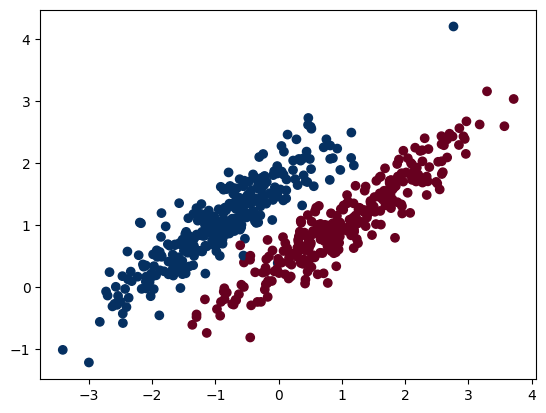

In [ ]:
# 1. 데이터 부르기
x,y = ds.make_classification(n_features=2, n_classes=2, n_informative=2,
                             n_samples=600, n_clusters_per_class=1, n_redundant=0)
# 2. 데이터 확인
plt.scatter(x[:,0],x[:,1],c=y, cmap=plt.cm.RdBu)
plt.show()

voting score : 0.99
[1 1 1 ... 1 1 1]


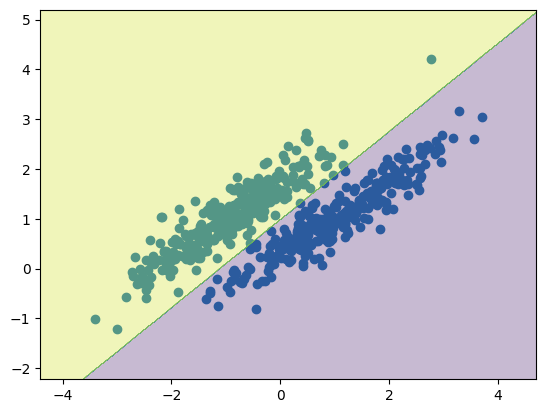

voting score : 0.86
[1 1 1 ... 0 0 0]


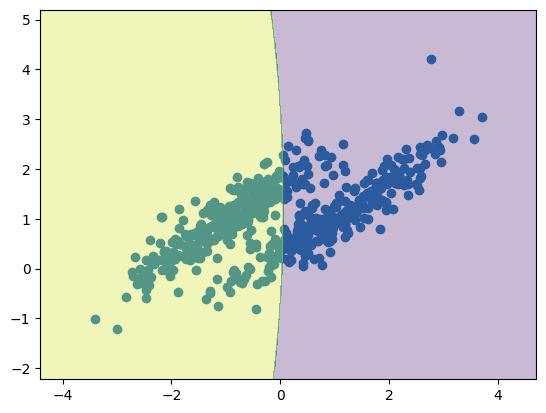

voting score : 0.99
[1 1 1 ... 0 0 0]


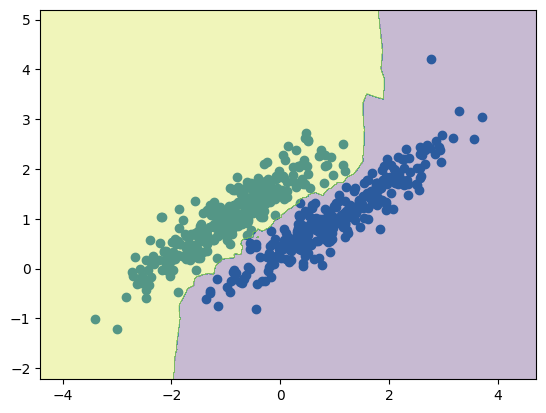

voting score : 0.98
[1 1 1 ... 0 0 0]


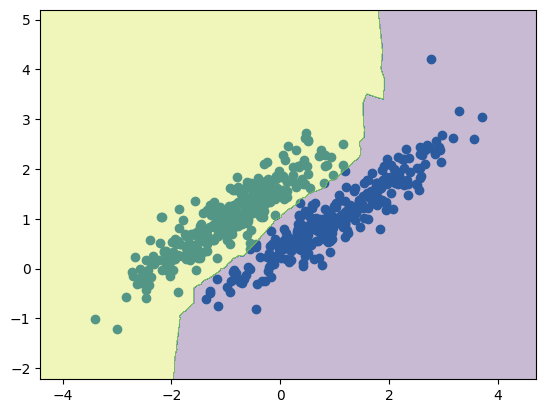

In [ ]:
# 3. 데이터 분할(상황에 따라서는 하지 않을수도 있다.)
# 4. 모델선정 및 훈련
model1 = ln.LogisticRegression()
model2 = nb.GaussianNB()
model3 = ne.KNeighborsClassifier(n_neighbors=3)

# 'lr','nb','ne' 등의 문자는 식별에 의미가 있으므로 임의로 변경해도 된다.(다만 중복은 안됨)
ensemble = en.VotingClassifier(
  estimators=[('lr',model1),('nb',model2),('ne',model3)]
  , voting='soft'
)

for model in [model1,model2,model3, ensemble]:
  model.fit(x,y)
  score = ms.cross_val_score(model,x,y,cv=5)
  print(f'voting score : {score.mean():.2f}')
  draw_area(x,y,model)
